In [2]:
import tensorflow as tf
from tensorflow.keras import models, layers
import numpy as np
from tensorflow.keras.datasets import fashion_mnist

In [3]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
print(x_train.shape)

(60000, 28, 28)


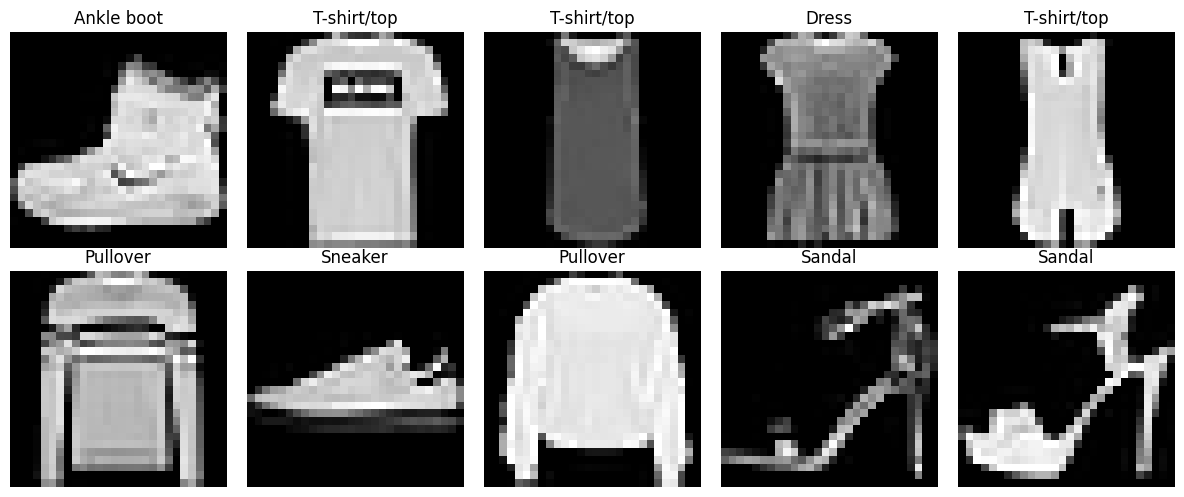

In [5]:
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
#validation spilt and normalization

from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.1,
    random_state= 42,
    stratify= y_train
)


x_train = tf.cast(x_train,tf.float32) / 255.0
x_val = tf.cast(x_val,tf.float32) / 255.0
x_test = tf.cast(x_test,tf.float32) / 255.0





In [7]:
#Baseline neural Network

model_neural = models.Sequential([
    layers.Input(shape=(28,28)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(128,activation="relu"),
    layers.Dense(64,activation="relu"),
    layers.Dense(10,activation="softmax")
])

model_neural.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67,466 (263.54 KB)

 Trainable params: 67,466 (263.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
#compilation
model_neural.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [9]:
#training the model

history_neural_10 = model_neural.fit(
    x_train,
    y_train,
    validation_data = (x_val,y_val),
    epochs = 10,
    batch_size = 128
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.7905 - loss: 0.5961 - val_accuracy: 0.8492 - val_loss: 0.4328
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8541 - loss: 0.4032 - val_accuracy: 0.8687 - val_loss: 0.3599
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8708 - loss: 0.3595 - val_accuracy: 0.8803 - val_loss: 0.3341
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8783 - loss: 0.3338 - val_accuracy: 0.8717 - val_loss: 0.3473
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8826 - loss: 0.3185 - val_accuracy: 0.8862 - val_loss: 0.3125
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8875 - loss: 0.3039 - val_accuracy: 0.8880 - val_loss: 0.3072
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8915 - loss: 0.2905 - val_accuracy: 0.8913 - val_loss: 0.3010
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8975 - loss: 0.2769 - val_accuracy: 0.

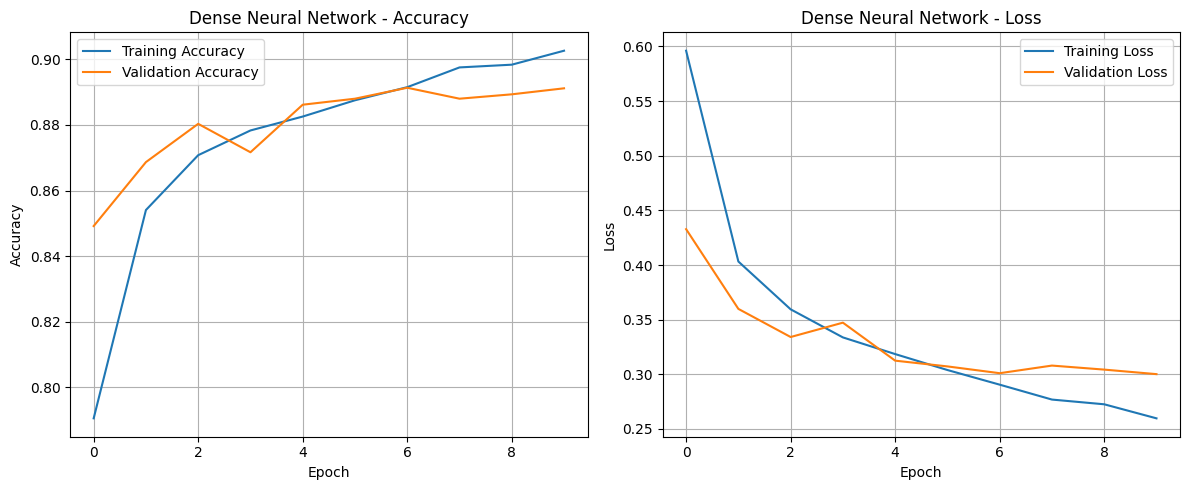

In [11]:
plt.figure(figsize=(12, 5))

# Accuracy plot
plt.subplot(1, 2, 1)
plt.plot(history_neural_10.history["accuracy"], label="Training Accuracy")
plt.plot(history_neural_10.history["val_accuracy"], label="Validation Accuracy")
plt.title("Dense Neural Network - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss plot
plt.subplot(1, 2, 2)
plt.plot(history_neural_10.history["loss"], label="Training Loss")
plt.plot(history_neural_10.history["val_loss"], label="Validation Loss")
plt.title("Dense Neural Network - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
model_cnn = tf.keras.Sequential([
    #conv block 1
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(filters=32,kernel_size=(3,3),padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPool2D(pool_size=(2,2)),

    #conv block 2
    layers.Conv2D(filters=64,kernel_size=(3,3),padding="same",activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPool2D(pool_size=(2,2)),

    layers.Flatten(),

    #Dense layers

    layers.Dense(64,activation="relu"),
    layers.Dropout(.2),
    layers.Dense(128,activation="relu"),
    layers.Dropout(.3),
    layers.Dense(64,activation="relu"),
    layers.Dropout(.2),
    layers.Dense(10,activation="softmax")




])

In [13]:
model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       200,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 237,194 (926.54 KB)

 Trainable params: 237,002 (925.79 KB)

 Non-trainable params: 192 (768.00 B)

In [14]:
#compiling cnn model

model_cnn.compile(
    optimizer = "adam",
    loss = ("sparse_categorical_crossentropy"),
    metrics = ["accuracy"]
)

In [15]:
#training

history_cnn = model_cnn.fit(
    x_train,
    y_train,
    validation_data = (x_val,y_val),
    epochs = 10,
    batch_size = 128
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 19s 25ms/step - accuracy: 0.7827 - loss: 0.6246 - val_accuracy: 0.8090 - val_loss: 0.5641
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8719 - loss: 0.3751 - val_accuracy: 0.9100 - val_loss: 0.2654
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8913 - loss: 0.3136 - val_accuracy: 0.9072 - val_loss: 0.2597
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9023 - loss: 0.2815 - val_accuracy: 0.9052 - val_loss: 0.2587
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9116 - loss: 0.2548 - val_accuracy: 0.9192 - val_loss: 0.2230
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9166 - loss: 0.2389 - val_accuracy: 0.9153 - val_loss: 0.2364
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9223 - loss: 0.2226 - val_accuracy: 0.9193 - val_loss: 0.2147
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9273 - loss: 0.2072 - val_accuracy: 

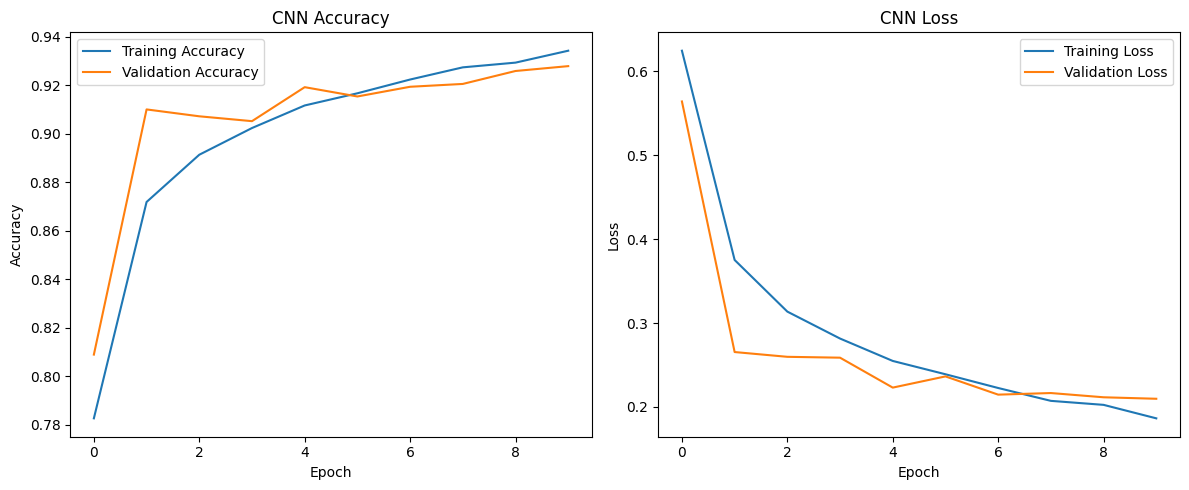

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
# Evaluate both models on the test set

dense_test_loss, dense_test_acc = model_neural.evaluate(
    x_test, y_test, verbose=0
)

cnn_test_loss, cnn_test_acc = model_cnn.evaluate(
    x_test, y_test, verbose=0
)

print(f"Dense NN Test Accuracy: {dense_test_acc:.4f}")
print(f"CNN Test Accuracy:     {cnn_test_acc:.4f}")

print(f"Dense NN Test Loss: {dense_test_loss:.4f}")
print(f"CNN Test Loss:     {cnn_test_loss:.4f}")

Dense NN Test Accuracy: 0.8788
CNN Test Accuracy:     0.9161
Dense NN Test Loss: 0.3458
CNN Test Loss:     0.2437


In [19]:
# Count trainable parameters
dense_params = sum(
    tf.keras.backend.count_params(w)
    for w in model_neural.trainable_weights
)

cnn_params = sum(
    tf.keras.backend.count_params(w)
    for w in model_cnn.trainable_weights
)


print(f"Dense NN trainable parameters: {dense_params:,}")
print(f"CNN trainable parameters:      {cnn_params:,}")

print(f"\nDense NN test accuracy: {dense_test_acc:.4%}")
print(f"CNN test accuracy:      {cnn_test_acc:.4%}")

if cnn_params < dense_params:
    print("\nCNN uses fewer trainable parameters.")
else:
    print("\nCNN uses more trainable parameters.")

print(
    f"Test accuracy difference: "
    f"{(cnn_test_acc - dense_test_acc) * 100:+.2f} percentage points"
)

Dense NN trainable parameters: 67,466
CNN trainable parameters:      237,002

Dense NN test accuracy: 87.8800%
CNN test accuracy:      91.6100%

CNN uses more trainable parameters.
Test accuracy difference: +3.73 percentage points


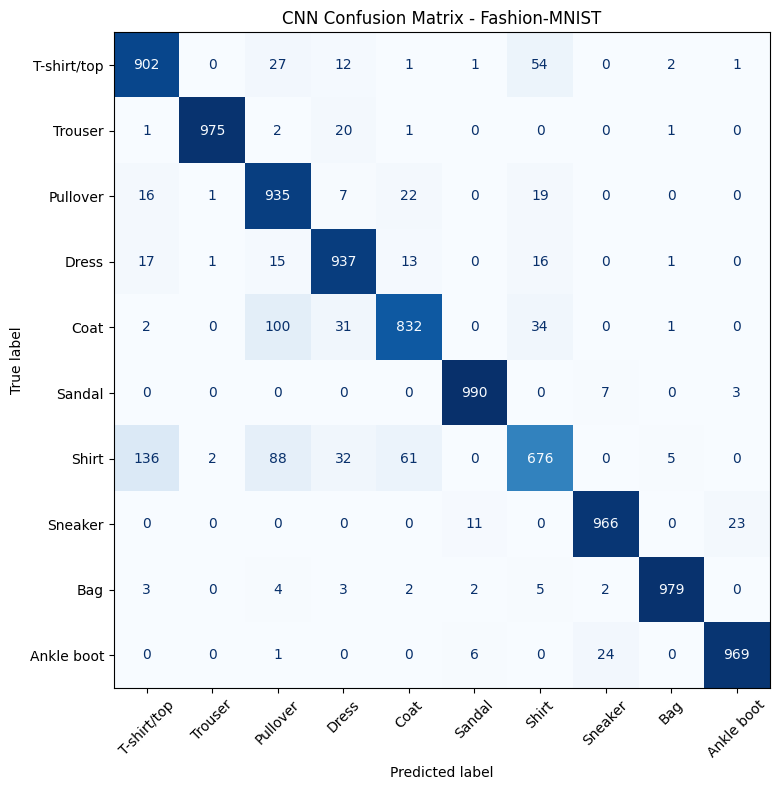

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Fashion-MNIST class names
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Predict test labels using CNN
cnn_predictions = model_cnn.predict(x_test, verbose=0)
y_pred = np.argmax(cnn_predictions, axis=1)

# Actual labels
y_true = np.asarray(y_test).reshape(-1)

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=range(10))

# Plot
fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("CNN Confusion Matrix - Fashion-MNIST")
plt.tight_layout()
plt.show()

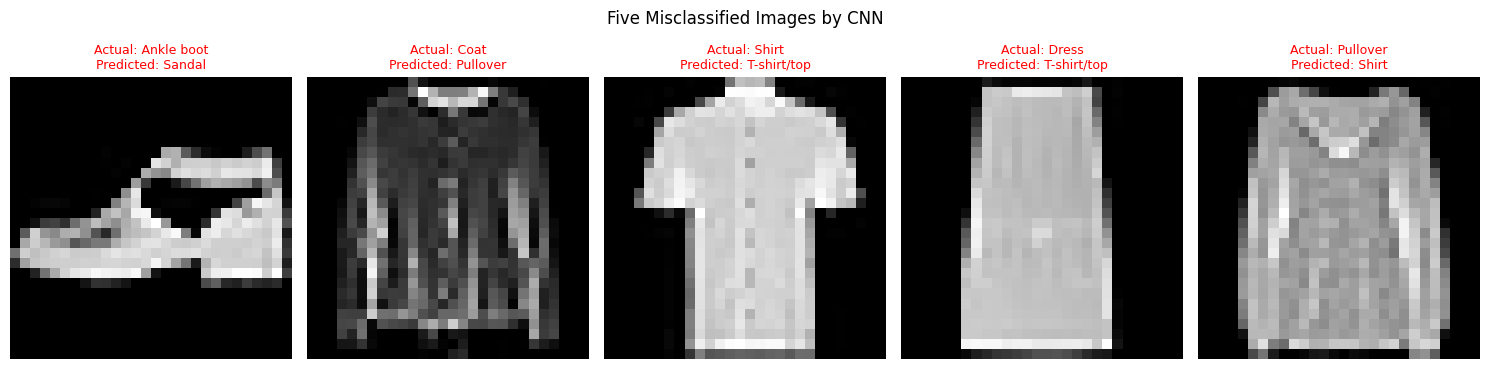

In [21]:
# Find indices where predictions are incorrect
misclassified_indices = np.where(y_pred != y_true)[0]

# Select up to five misclassified images
num_images = min(5, len(misclassified_indices))
selected_indices = misclassified_indices[:num_images]

plt.figure(figsize=(15, 4))

for i, idx in enumerate(selected_indices):
    plt.subplot(1, num_images, i + 1)

    # Squeeze removes a single channel dimension if present
    image = np.squeeze(x_test[idx])
    plt.imshow(image, cmap="gray")

    actual_label = class_names[y_true[idx]]
    predicted_label = class_names[y_pred[idx]]

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}",
        color="red",
        fontsize=9
    )

    plt.axis("off")

plt.suptitle("Five Misclassified Images by CNN")
plt.tight_layout()
plt.show()

# Reflection: Dense Neural Network vs. CNN

This experiment compares a Dense Neural Network with a Convolutional Neural Network (CNN) using the Fashion-MNIST dataset, which contains grayscale images of ten different clothing categories.

The Dense Neural Network takes each 28 × 28 image and flattens it into a one-dimensional vector. While this allows the model to learn relationships between pixels, it loses the original spatial arrangement of the image. As a result, the network has to learn important visual patterns through its fully connected layers.

On the other hand, the CNN is designed to work with images more effectively. It uses convolutional filters to detect basic features such as edges, textures, and shapes. As the data passes through multiple convolutional and pooling layers, the network learns more complex features that help it recognize different clothing items. Another advantage is weight sharing, which allows the same filters to be applied across different parts of an image, reducing the number of parameters and making the model more efficient for image classification.

In this experiment, the Dense Neural Network achieved approximately 89.12% validation accuracy, while the CNN reached approximately 92.78%. These results suggest that the CNN performs better at recognizing patterns in the Fashion-MNIST dataset. However, the final comparison should also consider the test accuracy of both models, along with their number of trainable parameters, to better understand their performance and complexity.

Overfitting is another important factor to consider when evaluating a model. It happens when a model performs well on training data but struggles to generalize to unseen examples. Training and validation accuracy and loss curves can help identify this problem. Over the ten training epochs, the CNN showed consistent improvement in training performance, while validation performance also generally improved. This suggests that there was no clear sign of severe overfitting during this experiment. Techniques such as batch normalization and dropout can also help stabilize training and reduce the risk of overfitting.

Some clothing categories look very similar, which can make classification difficult. The confusion matrix and misclassified images help identify where the models struggle most. For example, shirts, T-shirts, pullovers, and coats can have similar shapes and textures, especially in small grayscale images. This makes it harder for the model to distinguish between them accurately.

There are several ways to improve the results in future experiments. These include adjusting the learning rate, applying data
